<a href="https://colab.research.google.com/github/Nikhil14082005/Real-Estate-Investment-Advisor/blob/main/Real_Estate_Investment_Advisor_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real Estate Investment Advisor
## Predicting Property Profitability & Future Value

**Name:** Nikhil Satish Sonawane  
**Team:** Individual

**Github:** https://github.com/Nikhil14082005/Real-Estate-Investment-Advisor

**Colab-ready, single-notebook workflow** for the supplied real-estate dataset.

This notebook builds two models:
1. **Regression:** predict `Price_After_5_Years`.
2. **Classification:** predict whether a property is a **Good Investment (Yes/No)**.

It includes data loading, data checks, EDA, preprocessing, model training/comparison, evaluation, saving models, and generating a Streamlit app file.

## 1. Upload and Load the Dataset

In Google Colab, run this cell and upload `merged_houseprice_regression_classification(1).xlsx`.

The notebook uses the `Regression+Class` sheet. It can also read the file from the current working folder if already available.

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import joblib

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


# Automatically find CSV or Excel dataset in Colab Files section
data_files = [
    file for file in os.listdir("/content")
    if file.lower().endswith((".csv", ".xlsx", ".xls"))
    and not file.startswith("~$")
]

if not data_files:
    raise FileNotFoundError(
        "Dataset not found! Upload your CSV or Excel file "
        "into the Colab Files section and run this cell again."
    )

# Automatically select the dataset
DATA_PATH = data_files[0]

# Load CSV or Excel file
if DATA_PATH.lower().endswith(".csv"):
    df = pd.read_csv(DATA_PATH)

else:
    excel = pd.ExcelFile(DATA_PATH)

    if "Regression+Class" in excel.sheet_names:
        df = pd.read_excel(DATA_PATH, sheet_name="Regression+Class")
    else:
        df = pd.read_excel(DATA_PATH, sheet_name=0)

print("Dataset loaded successfully!")
print("File name:", DATA_PATH)
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File name: merged_houseprice_regression_classification.xlsx
Dataset shape: (500, 15)


,Property_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location_Score,School_Score,Current_Price,Price_Year_1,Price_Year_2,Price_Year_3,Price_Year_4,Price_After_5_Years,Price_Category
0,1,2751,3,4,3,1989,54,58,624636,656833,690689,726290,763726,803092,Medium
1,2,3322,5,1,1,2019,62,78,694237,729166,765853,804385,844856,887363,Medium
2,3,4765,3,3,2,1989,57,50,771778,803688,836917,871520,907554,945078,Medium
3,4,4512,2,2,3,2004,57,90,792597,854577,921404,993457,1071144,1154906,High
4,5,2436,3,1,1,1987,76,69,580257,612034,645552,680905,718194,757525,Low


## 2. Understand the Dataset

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Unique Values": df.nunique(),
    "Missing Values": df.isnull().sum()
}))

Rows: 500
Columns: 15

Column names:
['Property_ID', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Location_Score', 'School_Score', 'Current_Price', 'Price_Year_1', 'Price_Year_2', 'Price_Year_3', 'Price_Year_4', 'Price_After_5_Years', 'Price_Category']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Property_ID          500 non-null    int64 
 1   Area_sqft            500 non-null    int64 
 2   Bedrooms             500 non-null    int64 
 3   Bathrooms            500 non-null    int64 
 4   Floors               500 non-null    int64 
 5   Year_Built           500 non-null    int64 
 6   Location_Score       500 non-null    int64 
 7   School_Score         500 non-null    int64 
 8   Current_Price        500 non-null    int64 
 9   Price_Year_1         500 non-null    int64 
 10

,Data Type,Unique Values,Missing Values
Property_ID,int64,500,0
Area_sqft,int64,465,0
Bedrooms,int64,5,0
Bathrooms,int64,4,0
Floors,int64,3,0
Year_Built,int64,44,0
Location_Score,int64,50,0
School_Score,int64,61,0
Current_Price,int64,500,0
Price_Year_1,int64,500,0


## 3. Define the ML Targets

### Regression target
`Price_After_5_Years`

### Classification target
`Good_Investment` (Yes/No), derived from the property's five-year appreciation rate:

`Appreciation_Rate = ((Price_After_5_Years - Current_Price) / Current_Price) * 100`

The project brief does not specify an exact appreciation threshold. For a transparent starting point, this notebook uses **35% total appreciation over five years** as a configurable example threshold. Change `APPRECIATION_THRESHOLD` below if your instructor/business rules specify another value.

- Appreciation **greater than or equal to** the threshold → `Good Investment = Yes`
- Appreciation below the threshold → `Good Investment = No`

The future price is used only to create the training label/target, **never as an input feature**. Future-price columns are excluded from predictors to prevent leakage.

In [5]:
APPRECIATION_THRESHOLD = 35.0  # percent over 5 years; change if your project specifies another threshold

required_columns = [
    "Area_sqft", "Bedrooms", "Bathrooms", "Floors", "Year_Built",
    "Location_Score", "School_Score", "Current_Price", "Price_After_5_Years"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Remove rows without either target or a valid current price.
df = df.dropna(subset=["Current_Price", "Price_After_5_Years"]).copy()
df = df[df["Current_Price"] > 0].copy()

df["Appreciation_Rate"] = (
    (df["Price_After_5_Years"] - df["Current_Price"]) / df["Current_Price"]
) * 100

df["Good_Investment"] = np.where(
    df["Appreciation_Rate"] >= APPRECIATION_THRESHOLD, "Yes", "No"
)

print(f"Good Investment threshold: {APPRECIATION_THRESHOLD:.1f}% over five years")
display(df[["Current_Price", "Price_After_5_Years", "Appreciation_Rate", "Good_Investment"]].head())
print("\nClassification target counts:")
display(df["Good_Investment"].value_counts().to_frame("Count"))
print("\nClassification target percentages:")
display((df["Good_Investment"].value_counts(normalize=True) * 100).round(1).to_frame("Percent"))

Good Investment threshold: 35.0% over five years


,Current_Price,Price_After_5_Years,Appreciation_Rate,Good_Investment
0,624636,803092,28.57,No
1,694237,887363,27.82,No
2,771778,945078,22.45,No
3,792597,1154906,45.71,Yes
4,580257,757525,30.55,No



Classification target counts:


,Count
Good_Investment,
Yes,262
No,238



Classification target percentages:


,Percent
Good_Investment,
Yes,52.40
No,47.60


## 4. Data Cleaning and Feature Selection

The input features are details available when evaluating a property. `Property_ID`, `Price_Year_1`–`Price_Year_4`, `Price_After_5_Years`, `Price_Category`, `Appreciation_Rate`, and `Good_Investment` are not predictors.

Missing numeric feature values, if any, are filled with the training-set median inside each pipeline. The chosen models use numerical features, so one-hot encoding is not needed.

In [6]:
FEATURES = [
    "Area_sqft", "Bedrooms", "Bathrooms", "Floors", "Year_Built",
    "Location_Score", "School_Score", "Current_Price"
]
REGRESSION_TARGET = "Price_After_5_Years"
CLASSIFICATION_TARGET = "Good_Investment"

X = df[FEATURES].copy()
y_reg = df[REGRESSION_TARGET].copy()
y_cls = df[CLASSIFICATION_TARGET].map({"No": 0, "Yes": 1})

# Ensure selected inputs are numeric; invalid values become missing and are imputed in pipelines.
X = X.apply(pd.to_numeric, errors="coerce")

print("Features:", FEATURES)
print("Regression target:", REGRESSION_TARGET)
print("Classification target:", CLASSIFICATION_TARGET)
print("\nMissing values in selected features:")
display(X.isnull().sum().to_frame("Missing Values"))
display(X.describe().T)

Features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Location_Score', 'School_Score', 'Current_Price']
Regression target: Price_After_5_Years
Classification target: Good_Investment

Missing values in selected features:


,Missing Values
Area_sqft,0
Bedrooms,0
Bathrooms,0
Floors,0
Year_Built,0
Location_Score,0
School_Score,0
Current_Price,0


,count,mean,std,min,25%,50%,75%,max
Area_sqft,500.00,"2,979.94","1,198.84",802.00,"1,956.25","2,999.50","4,027.50","4,973.00"
Bedrooms,500.00,3.02,1.41,1.00,2.00,3.00,4.00,5.00
Bathrooms,500.00,2.50,1.10,1.00,2.00,3.00,3.00,4.00
Floors,500.00,1.88,0.82,1.00,1.00,2.00,3.00,3.00
Year_Built,500.00,"2,000.86",12.91,"1,980.00","1,989.00","2,001.00","2,012.00","2,023.00"
Location_Score,500.00,75.14,14.60,50.00,62.00,75.50,88.00,100.00
School_Score,500.00,69.18,17.62,40.00,53.75,68.50,84.00,100.00
Current_Price,500.00,"660,302.21","154,418.60","295,602.00","539,024.50","663,950.50","781,156.75","1,010,002.00"


## 5. Exploratory Data Analysis (EDA)

These charts are intended to help understand price distribution and relationships before training.

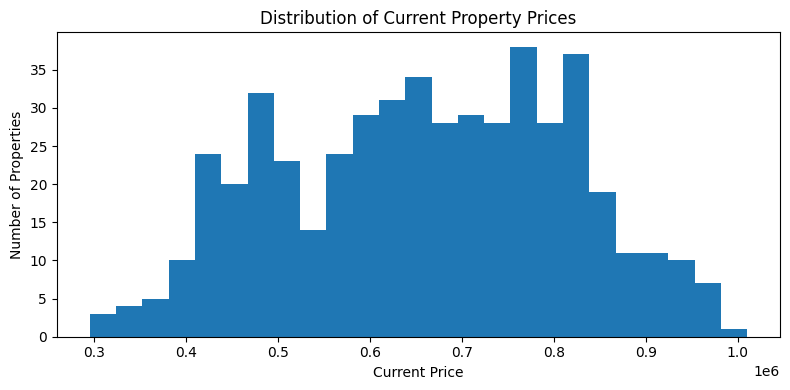

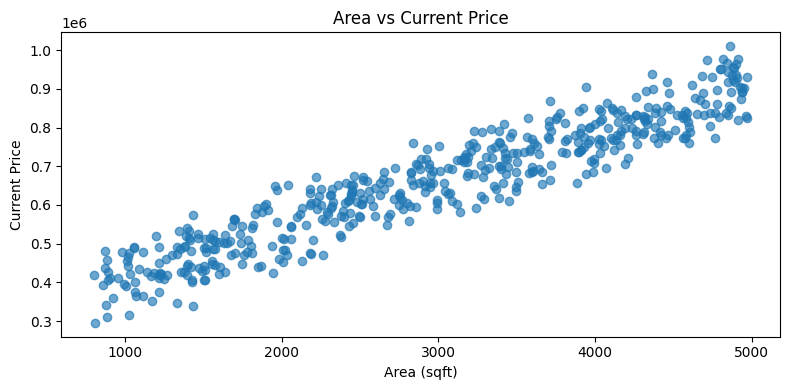

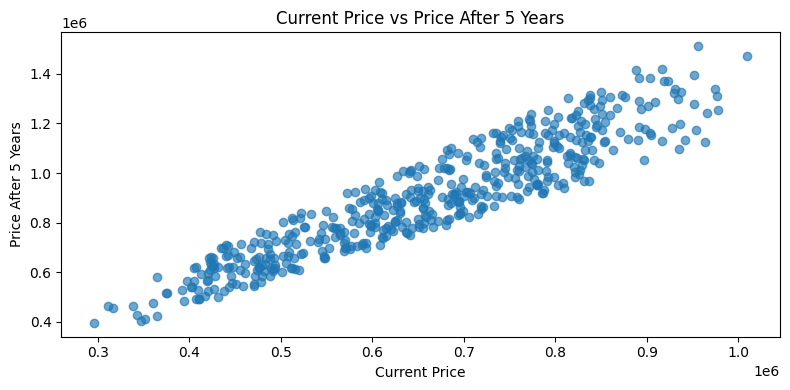

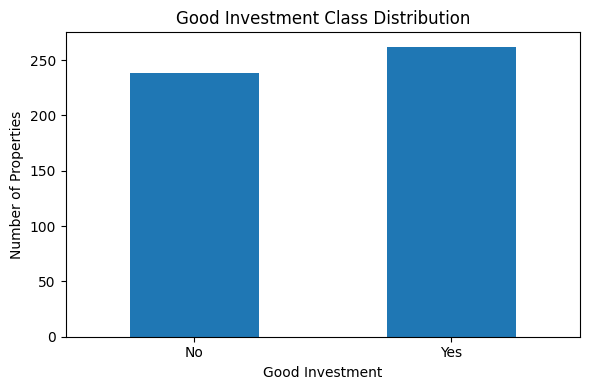

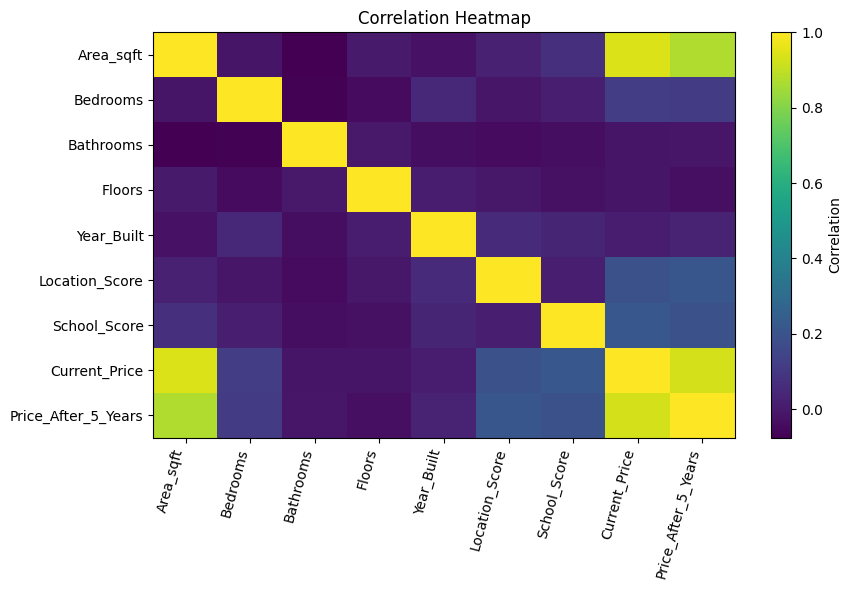

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(df["Current_Price"], bins=25)
plt.xlabel("Current Price")
plt.ylabel("Number of Properties")
plt.title("Distribution of Current Property Prices")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(df["Area_sqft"], df["Current_Price"], alpha=0.65)
plt.xlabel("Area (sqft)")
plt.ylabel("Current Price")
plt.title("Area vs Current Price")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(df["Current_Price"], df["Price_After_5_Years"], alpha=0.65)
plt.xlabel("Current Price")
plt.ylabel("Price After 5 Years")
plt.title("Current Price vs Price After 5 Years")
plt.tight_layout()
plt.show()

df["Good_Investment"].value_counts().reindex(["No", "Yes"]).plot(kind="bar", figsize=(6, 4))
plt.xlabel("Good Investment")
plt.ylabel("Number of Properties")
plt.title("Good Investment Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

corr = df[FEATURES + [REGRESSION_TARGET]].corr()
plt.figure(figsize=(9, 6))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Split the Data

We use an 80:20 train-test split. The same split is used for both tasks so model results are reproducible.

In [8]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.20, random_state=42
)

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X, y_cls, test_size=0.20, random_state=42, stratify=y_cls
)

print("Regression train/test shapes:", X_train_reg.shape, X_test_reg.shape)
print("Classification train/test shapes:", X_train_cls.shape, X_test_cls.shape)

Regression train/test shapes: (400, 8) (100, 8)
Classification train/test shapes: (400, 8) (100, 8)


## 7. Train and Compare Regression Models

Models: Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

- **MAE:** average absolute prediction error; lower is better.
- **RMSE:** penalizes large errors more strongly; lower is better.
- **R²:** proportion of target variation explained by the model; higher is generally better.

In [9]:
reg_models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=5, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42))
    ])
}

reg_rows = []
for name, model in reg_models.items():
    model.fit(X_train_reg, y_train_reg)
    pred = model.predict(X_test_reg)
    reg_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_reg, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, pred)),
        "R2": r2_score(y_test_reg, pred)
    })

reg_results = pd.DataFrame(reg_rows).sort_values("RMSE").reset_index(drop=True)
display(reg_results)

,Model,MAE,RMSE,R2
0,Linear Regression,"72,625.25","86,609.11",0.86
1,Random Forest,"80,063.41","98,199.33",0.82
2,Decision Tree,"83,596.82","101,957.34",0.80


## 8. Train and Compare Classification Models

The target is **Good Investment = Yes/No**, not the dataset's `Price_Category` (Low/Medium/High).

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** how often predicted positives are correct.
- **Recall:** how many actual positives are found.
- **F1-score:** balances precision and recall.

In [10]:
cls_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42))
    ])
}

cls_rows = []
for name, model in cls_models.items():
    model.fit(X_train_cls, y_train_cls)
    pred = model.predict(X_test_cls)
    cls_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_cls, pred),
        "Precision": precision_score(y_test_cls, pred, zero_division=0),
        "Recall": recall_score(y_test_cls, pred, zero_division=0),
        "F1": f1_score(y_test_cls, pred, zero_division=0)
    })

cls_results = pd.DataFrame(cls_rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(cls_results)

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.56,0.57,0.63,0.60
1,Decision Tree,0.57,0.59,0.58,0.58
2,Logistic Regression,0.50,0.52,0.54,0.53


## 9. Select the Best Models and Evaluate

Best regression model: Linear Regression
Best classification model: Random Forest

Regression evaluation
MAE: 72625.25
RMSE: 86609.11
R2: 0.8585


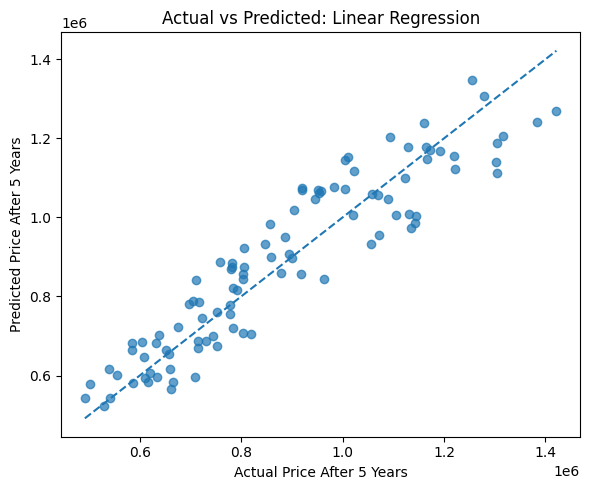


Classification evaluation
              precision    recall  f1-score   support

          No       0.55      0.48      0.51        48
         Yes       0.57      0.63      0.60        52

    accuracy                           0.56       100
   macro avg       0.56      0.56      0.56       100
weighted avg       0.56      0.56      0.56       100



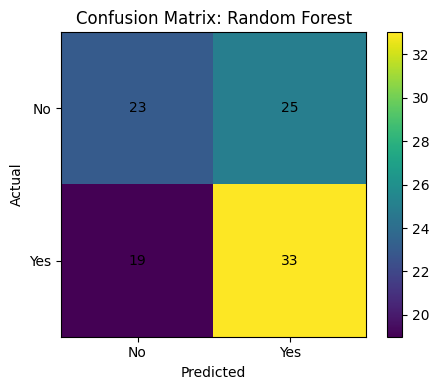

In [11]:
best_reg_name = reg_results.iloc[0]["Model"]
best_cls_name = cls_results.iloc[0]["Model"]
best_reg_model = reg_models[best_reg_name]
best_cls_model = cls_models[best_cls_name]

print("Best regression model:", best_reg_name)
print("Best classification model:", best_cls_name)

# Detailed regression evaluation
reg_pred = best_reg_model.predict(X_test_reg)
print("\nRegression evaluation")
print("MAE:", round(mean_absolute_error(y_test_reg, reg_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_reg, reg_pred)), 2))
print("R2:", round(r2_score(y_test_reg, reg_pred), 4))

plt.figure(figsize=(6, 5))
plt.scatter(y_test_reg, reg_pred, alpha=0.7)
low = min(y_test_reg.min(), reg_pred.min())
high = max(y_test_reg.max(), reg_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Price After 5 Years")
plt.ylabel("Predicted Price After 5 Years")
plt.title(f"Actual vs Predicted: {best_reg_name}")
plt.tight_layout()
plt.show()

# Detailed classification evaluation
cls_pred = best_cls_model.predict(X_test_cls)
print("\nClassification evaluation")
print(classification_report(
    y_test_cls, cls_pred, labels=[0, 1], target_names=["No", "Yes"], zero_division=0
))

cm = confusion_matrix(y_test_cls, cls_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.colorbar()
plt.xticks([0, 1], ["No", "Yes"])
plt.yticks([0, 1], ["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best_cls_name}")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

## 10. Feature Importance

Tree-based models can provide a simple view of which inputs are most influential. These importances describe model behavior, not proof that a feature causes a price change.

Regression Random Forest


,Importance
Current_Price,0.90
Area_sqft,0.02
Location_Score,0.02
Year_Built,0.02
School_Score,0.02
Bedrooms,0.01
Bathrooms,0.01
Floors,0.01


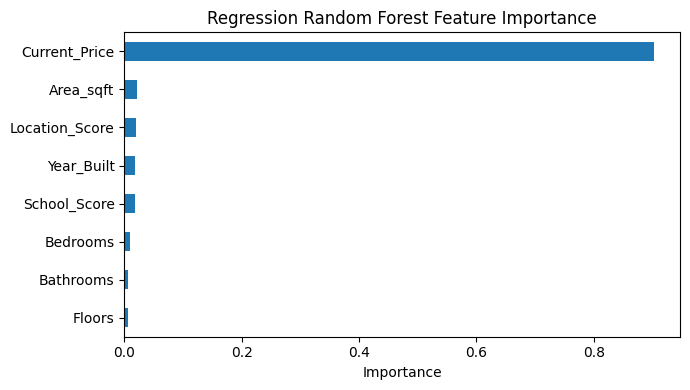

Classification Random Forest


,Importance
Area_sqft,0.18
Current_Price,0.17
Location_Score,0.17
Year_Built,0.16
School_Score,0.15
Bedrooms,0.06
Bathrooms,0.05
Floors,0.05


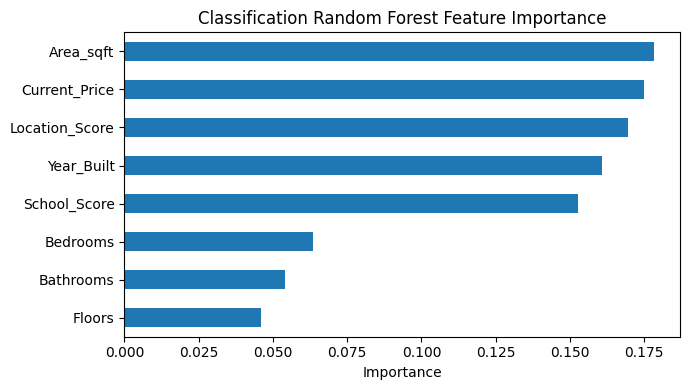

In [12]:
def get_tree_feature_importance(pipeline):
    model = pipeline.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        return pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
    return None

for title, model in [
    ("Regression Random Forest", reg_models["Random Forest"]),
    ("Classification Random Forest", cls_models["Random Forest"])
]:
    importance = get_tree_feature_importance(model)
    print(title)
    display(importance.to_frame("Importance"))
    importance.sort_values().plot(kind="barh", figsize=(7, 4), title=title + " Feature Importance")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

## 11. Save Models and Project Settings

The model files and configuration are saved so they can be reused by a Streamlit application.

In [13]:
joblib.dump(best_reg_model, "best_regression_model.joblib")
joblib.dump(best_cls_model, "best_classification_model.joblib")
joblib.dump({
    "features": FEATURES,
    "appreciation_threshold": APPRECIATION_THRESHOLD,
    "regression_target": REGRESSION_TARGET,
    "classification_target": CLASSIFICATION_TARGET
}, "model_config.joblib")

print("Saved:")
print("- best_regression_model.joblib")
print("- best_classification_model.joblib")
print("- model_config.joblib")

Saved:
- best_regression_model.joblib
- best_classification_model.joblib
- model_config.joblib


## 12. Try a Prediction

Change the example property values to test your own scenario. Use the same units and sensible ranges as the training dataset.

In [14]:
sample_property = pd.DataFrame([{
    "Area_sqft": 3000,
    "Bedrooms": 3,
    "Bathrooms": 2,
    "Floors": 2,
    "Year_Built": 2015,
    "Location_Score": 80,
    "School_Score": 75,
    "Current_Price": 700000
}])[FEATURES]

predicted_5_year_price = best_reg_model.predict(sample_property)[0]
investment_prediction = int(best_cls_model.predict(sample_property)[0])

print(f"Estimated price after 5 years: {predicted_5_year_price:,.2f}")
print("Good Investment:", "YES" if investment_prediction == 1 else "NO")

if hasattr(best_cls_model, "predict_proba"):
    probability = best_cls_model.predict_proba(sample_property)[0]
    classes = best_cls_model.classes_
    yes_index = list(classes).index(1)
    print(f"Model probability for Good Investment = YES: {probability[yes_index] * 100:.1f}%")

Estimated price after 5 years: 962,810.45
Good Investment: NO
Model probability for Good Investment = YES: 35.6%


## 13. Generate the Streamlit App

This cell creates an `app.py` file for a simple interactive Streamlit interface. The app uses the trained model files created above and shows the five-year price estimate, Good Investment prediction, confidence probability, and a small EDA chart.

To run it later in Colab, install Streamlit and run the generated `app.py` in an environment that supports Streamlit.

In [15]:
app_code = r'''
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Real Estate Investment Advisor", page_icon="🏡", layout="wide")
st.title("🏡 Real Estate Investment Advisor")
st.write("Estimate a property's value after five years and assess whether it meets the configured investment-appreciation rule.")

reg_model = joblib.load("best_regression_model.joblib")
cls_model = joblib.load("best_classification_model.joblib")
config = joblib.load("model_config.joblib")
features = config["features"]
threshold = config["appreciation_threshold"]

st.info(f"Classification rule: Good Investment = Yes when estimated/observed five-year appreciation reaches {threshold:.1f}%. This model predicts the label learned from the training data.")

with st.form("property_form"):
    c1, c2 = st.columns(2)
    with c1:
        area = st.number_input("Area (sqft)", min_value=100, max_value=50000, value=3000)
        bedrooms = st.number_input("Bedrooms", min_value=0, max_value=20, value=3)
        bathrooms = st.number_input("Bathrooms", min_value=0, max_value=20, value=2)
        floors = st.number_input("Floors", min_value=0, max_value=100, value=2)
    with c2:
        year_built = st.number_input("Year Built", min_value=1800, max_value=2100, value=2015)
        location_score = st.slider("Location Score", min_value=0, max_value=100, value=80)
        school_score = st.slider("School Score", min_value=0, max_value=100, value=75)
        current_price = st.number_input("Current Price", min_value=1.0, value=700000.0, step=10000.0)
    submitted = st.form_submit_button("Analyze Property")

if submitted:
    row = pd.DataFrame([{
        "Area_sqft": area, "Bedrooms": bedrooms, "Bathrooms": bathrooms,
        "Floors": floors, "Year_Built": year_built, "Location_Score": location_score,
        "School_Score": school_score, "Current_Price": current_price
    }])[features]

    future_price = float(reg_model.predict(row)[0])
    appreciation = ((future_price - current_price) / current_price) * 100

    good_investment = appreciation >= threshold

    left, right = st.columns(2)

    left.metric("Estimated Price After 5 Years", f"₹{future_price:,.2f}")
    right.metric("Appreciation", f"{appreciation:.2f}%")

    st.subheader("Investment Recommendation")
    st.success("GOOD INVESTMENT: YES") if good_investment else st.warning("GOOD INVESTMENT: NO")

    if hasattr(cls_model, "predict_proba"):
        probs = cls_model.predict_proba(row)[0]
        class_list = list(cls_model.classes_)

        if 1 in class_list:
            confidence = float(probs[class_list.index(1)])
            st.write(f"Classification Model Probability: {confidence:.1%}")
            st.progress(confidence)

    st.caption("Predictions are estimates, not guaranteed investment returns.")

st.subheader("Model Inputs")
st.write("The models use area, bedrooms, bathrooms, floors, construction year, location score, school score, and current price.")
'''
with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("Created app.py")
print("Streamlit run command: streamlit run app.py")
print("Keep app.py, best_regression_model.joblib, best_classification_model.joblib, and model_config.joblib in the same folder.")

Created app.py
Streamlit run command: streamlit run app.py
Keep app.py, best_regression_model.joblib, best_classification_model.joblib, and model_config.joblib in the same folder.


## 14. Download Project Files in Google Colab

Run this cell to download the notebook outputs (model files and Streamlit app) one by one.

In [16]:
# In Google Colab, uncomment the files.download lines for the files you want to download.
try:
    from google.colab import files
    # files.download("best_regression_model.joblib")
    # files.download("best_classification_model.joblib")
    # files.download("model_config.joblib")
    # files.download("app.py")
    print("To download files, uncomment the relevant files.download(...) line(s).")
except ImportError:
    print("Not running in Google Colab. Files are saved in the current working directory.")

To download files, uncomment the relevant files.download(...) line(s).


##15. Running Streamlit App

In [17]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 17.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 45.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [streamlit]


In [18]:
!ls -lh /content/

total 2.9M
-rw-r--r-- 1 root root 3.0K Nov  3 09:30 app.py
-rw-r--r-- 1 root root 2.8M Nov  3 09:29 best_classification_model.joblib
-rw-r--r-- 1 root root 2.0K Nov  3 09:29 best_regression_model.joblib
-rw-r--r-- 1 root root  64K Nov  3 09:27 merged_houseprice_regression_classification.xlsx
-rw-r--r-- 1 root root  254 Nov  3 09:29 model_config.joblib
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data


In [20]:
!pip install -q streamlit pyngrok joblib pandas matplotlib

In [21]:
!pkill -f '[s]treamlit run' || true

In [22]:
!cd /content && streamlit run app_v2.py --server.port 8501 --server.address 0.0.0.0 > /content/logs.txt 2>&1 &

In [ ]:
import subprocess

log = open("/content/logs.txt", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app_v2.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    stdout=log,
    stderr=log
)

print("Streamlit started successfully!")

In [35]:
!pkill -f '[s]treamlit run' || true

In [40]:
!cat /content/logs.txt

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/app_v2.py


In [41]:
from pyngrok import ngrok

# Kill any existing tunnels
ngrok.kill()

# Paste your ngrok authtoken here if you have one:
# Get it from: https://dashboard.ngrok.com/get-started/your-authtoken
NGROK_AUTH_TOKEN = "YOUR_NGROK_AUTHTOKEN_HERE"

if NGROK_AUTH_TOKEN != "YOUR_NGROK_AUTHTOKEN_HERE":
    ngrok.set_auth_token(NGROK_AUTH_TOKEN)
    public_url = ngrok.connect(8501)
    print("Your Dashboard URL:", public_url)
else:
    print("Please replace 'YOUR_NGROK_AUTHTOKEN_HERE' with your actual ngrok token to start the tunnel.")

Please replace 'YOUR_NGROK_AUTHTOKEN_HERE' with your actual ngrok token to start the tunnel.


## Conclusion

This single notebook covers both required tasks:
- **Regression:** predict `Price_After_5_Years`.
- **Classification:** predict **Good Investment (Yes/No)** using a configurable appreciation threshold.

The classification target is not `Price_Category`. The threshold in this notebook is an explicit example because the supplied project brief does not give a fixed numeric threshold. Confirm or change it according to your instructor's guidance.

The notebook also generates `app_v2.py` for a Streamlit interface. Actual deployment to Streamlit Cloud is a separate step and requires uploading the app and its model/config files.